# Dynamic Programming e Grafos – Escadas rolantes da Linha 4 (Motiva)

**Challenge FIAP × Motiva.** Este notebook roda de ponta a ponta e cobre:

1. **Dados** – notas de manutenção do SAP das escadas rolantes (2009–2026)
2. **Degradação acumulada** – recursiva pura, memoizada (dicionário) e tabulada; medição e ranking de criticidade
3. **Rede de estações** – grafo com lista de adjacência, BFS (menos trechos) e Dijkstra (menor tempo), com reconstrução de rotas
4. **A\*** – heurística geográfica justificada e comparação com Dijkstra
5. **Plano de manutenção** – `planejar_turno(base, horas)`

> **Sobre o dataset.** O enunciado cita sensores (vibração, temperatura, corrente/tensão, óleo, velocidade), mas os
> dados recebidos da Motiva são **notas de manutenção do SAP** – não há leituras de sensores. Cada nota datada é
> tratada como uma *leitura* do estado da escada, e o dano de cada leitura é calculado a partir de campos reais
> (tipo de nota, indisponibilidade, falha, duração da parada e defeito). Sintomas como *ruído anormal*,
> *nível de óleo baixo* e *não reduz velocidade* aparecem nas notas e fazem o papel dos sinais de sensor.

In [1]:
import sys, time, json, math, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))
from src.degradacao import (dano_evento, adicionar_dano, leituras_mensais, degradacao_recursiva,
                            degradacao_memoizada, degradacao_tabulada, ranking_criticidade)
from src.grafo import (carregar_rede, bfs, dijkstra, a_estrela, reconstruir_rota, custo_rota,
                       haversine_km, velocidade_maxima, heuristica_tempo, grade_sintetica)
from src.planejamento import planejar_turno, exibir_plano, tempos_reparo

DATA, FIGS = Path('data'), Path('figs')
FIGS.mkdir(exist_ok=True)
pd.set_option('display.width', 140)

# Estilo dos gráficos: marcas finas, grade discreta, paleta categórica em ordem fixa
CORES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
                     'axes.edgecolor': '#8a8984', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e',
                     'ytick.color': '#52514e', 'axes.titleweight': 'bold', 'axes.titlesize': 11,
                     'lines.linewidth': 2, 'font.size': 9.5, 'legend.frameon': False})

## 1. Dados

Os CSVs em `data/` foram gerados por `scripts/preparar_dados.py` a partir das exportações brutas
(`ecr_AAAA.XLSX`). Regras de limpeza: remoção de notas duplicadas, descarte de notas canceladas/duplicadas
no SAP e de linhas sem escada identificada, e duração da avaria aceita apenas entre 0 e 30 dias.

| Tipo de nota | Significado (inferido do conteúdo) | Entra no desgaste? |
|---|---|---|
| Z1 | Falha corretiva – 85 % deixam a escada indisponível | Sim (peso 2) |
| Z7 | Reparo de componente estrutural (tramo, degrau) | Sim (peso 1,5) |
| Z2 | Anomalia sem parada (ruído, óleo baixo, velocidade) | Sim (peso 1) |
| Z3 | Preventiva programada | Não – é manutenção, não desgaste |
| Z8 / Z9 | Melhoria / serviço | Não |

In [2]:
eventos = pd.read_csv(DATA / 'eventos_escadas.csv', parse_dates=['inicio', 'fim'])
escadas = pd.read_csv(DATA / 'escadas.csv')
print(f"Eventos datados: {len(eventos):,} | escadas: {eventos.escada.nunique()} | estações: {eventos.estacao.nunique()}")
print(f"Período: {eventos.inicio.min():%d/%m/%Y} a {eventos.inicio.max():%d/%m/%Y}")
display(eventos.tipo.value_counts().rename('notas').to_frame().T)
display(escadas.groupby('estacao').escada.count().rename('escadas por estação').to_frame().T)
eventos.head(3)

Eventos datados: 71,966 | escadas: 199 | estações: 12
Período: 10/11/2009 a 22/09/2026


tipo,Z1,Z2,Z3,Z7,Z8,Z9,Z5
notas,42511,20383,8603,256,137,74,2


estacao,BUT,FAL,FRA,FRE,HIG,LUZ,MBI,PIN,PTA,REP,TVS,VSO
escadas por estação,14,10,10,20,26,20,13,32,18,7,9,20


,nota,tipo,escada,estacao,inicio,fim,duracao_min,indisponivel,falha,descricao,defeito,sintoma,causa,acao,objeto
0,10011613,Z1,BUT-ER01,BUT,2011-04-06 08:20:00,2011-09-24 09:00:00,NaN,0,0,ER - 01 Vazamento de óleo,DANIFICADO(A),ALARME-PLACA PENTE SUPERIOR ESQUERDO,IMPERMEABILIZACAO INADEQUADA,LIMPO(A),GABINETE
1,10012121,Z1,BUT-ER01,BUT,2011-04-13 12:30:00,2011-04-13 13:00:00,30.0,0,0,ER-01 com barulho no poço superior,SOLTO,ALARME-BLOQUEIO DE FREIO 2 DIREITO,PARAFUSO DESAPERTADO,APERTADO(A),GABINETE
2,10012626,Z2,BUT-ER01,BUT,2011-04-26 21:17:11,2011-04-26 21:18:00,0.8,0,0,Limpeza de óleo ER01 BUT,DANIFICADO(A),ALARME-PLACA PENTE SUPERIOR ESQUERDO,ACUMULO DE RESIDUO,LIMPO(A),BOMBA LUBRIFICACAO AUTOMATICA


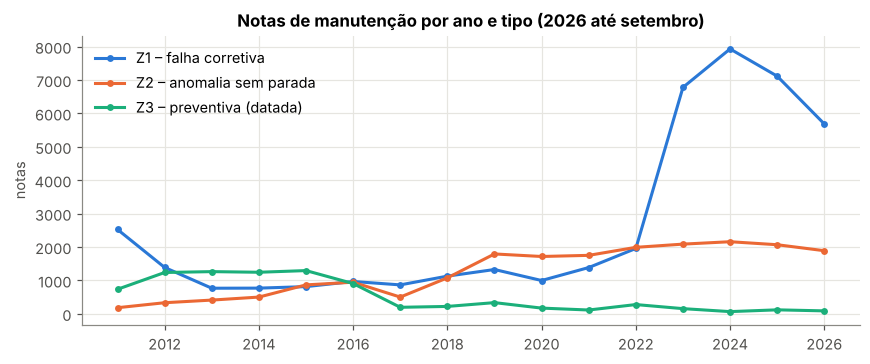

In [3]:
anual = eventos[eventos.tipo.isin(['Z1', 'Z2', 'Z3'])].groupby([eventos.inicio.dt.year, 'tipo']).size().unstack(fill_value=0)
anual = anual.loc[2011:]
fig, ax = plt.subplots(figsize=(8, 3.4))
rotulo = {'Z1': 'Z1 – falha corretiva', 'Z2': 'Z2 – anomalia sem parada', 'Z3': 'Z3 – preventiva (datada)'}
for cor, tipo in zip(CORES, ['Z1', 'Z2', 'Z3']):
    ax.plot(anual.index, anual[tipo], color=cor, marker='o', markersize=3.5, label=rotulo[tipo])
ax.set_title('Notas de manutenção por ano e tipo (2026 até setembro)')
ax.set_ylabel('notas'); ax.legend(loc='upper left')
fig.tight_layout(); fig.savefig(FIGS / 'notas_por_ano.png'); plt.show()

**Interpretação.** A base tem 71.966 notas datadas de 199 escadas em 12 estações. O ponto de atenção é a quebra de série em 2023: as falhas corretivas (Z1) saltam de 1.956 em 2022 para 6.778 em 2023. Isso não significa que as escadas passaram a quebrar 3,5× mais; 77 % das Z1 a partir de 2023 têm a descrição padronizada *Falha Técnica* (contra praticamente 0 % antes) e 65 % foram resolvidas com *resetado e testado*. Ou seja, a partir de 2023 as paradas passaram a ser registradas automaticamente, inclusive as curtas. Consequências para o modelo: (1) o valor absoluto da degradação é maior depois de 2023 e não deve ser comparado com anos anteriores; (2) o ranking compara todas as escadas **no mesmo mês**, sob o mesmo regime de registro, então continua justo; (3) o fator de esquecimento da recorrência faz o passado pesar pouco no valor atual.

## 2. Degradação acumulada – três versões

**Dano de cada evento** (`dano_evento`):

`dano = peso_tipo + 2·indisponível + 1·falha + min(ln(1 + horas paradas), 3) + ajuste_defeito`

com `ajuste_defeito = +1` para defeitos graves (quebrado, danificado, desgastado, travamento…) e `−0,5` para
"nada constatado". Os danos são somados **por mês e por escada**, formando as leituras `d[0..n-1]`
(jan/2010 a set/2026, n = 201).

**Recorrência** – a degradação de hoje é o dano novo mais uma fração do desgaste dos dois meses anteriores
(a manutenção recupera o resto):

$$D(i) = d_i + a\,D(i-1) + b\,D(i-2), \qquad D(-1) = D(-2) = 0, \quad a = 0{,}6,\; b = 0{,}2$$

Como há **dois** termos recursivos, a recursão pura resolve os mesmos subproblemas muitas vezes
(nº de chamadas cresce como Fibonacci, ~1,6ⁿ) – exatamente o cenário em que memoização e tabulação ajudam.

In [4]:
eventos = adicionar_dano(eventos)
print(eventos.groupby('tipo').dano.agg(['count', 'mean', 'max']).round(2).loc[['Z1', 'Z7', 'Z2', 'Z3']])
leituras = leituras_mensais(eventos)
print(f"\nMatriz de leituras: {leituras.shape[0]} escadas × {leituras.shape[1]} meses "
      f"({leituras.columns[0]} a {leituras.columns[-1]})")
leituras.iloc[:3, -6:]

      count  mean  max
tipo                  
Z1    42511  4.83  9.0
Z7      256  1.65  4.5
Z2    20383  3.40  8.0
Z3     8603  0.00  0.0

Matriz de leituras: 198 escadas × 201 meses (2010-01 a 2026-09)


,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
escada,,,,,,
BUT-ER01,16.094679,17.171174,32.761351,38.372875,25.173531,16.563786
BUT-ER02,18.024374,4.693147,14.323228,15.984579,21.647985,5.827095
BUT-ER03,20.271053,0.000000,13.085258,0.000000,43.975411,8.456975


### 2.1 As três implementações dão o mesmo resultado?

Teste em **todas as escadas**: a recursiva pura roda numa janela dos últimos 20 meses (com a série inteira
ela não terminaria – ver 2.2); memoizada e tabulada rodam na série completa e também na janela.

In [5]:
JANELA = 20
dif_janela, dif_completa, t0 = 0.0, 0.0, time.perf_counter()
for esc, linha in leituras.iterrows():
    d = linha.to_numpy().tolist()
    w = d[-JANELA:]
    r, m, t = degradacao_recursiva(w), degradacao_memoizada(w), degradacao_tabulada(w)
    dif_janela = max(dif_janela, abs(r - m), abs(r - t))
    dif_completa = max(dif_completa, abs(degradacao_memoizada(d) - degradacao_tabulada(d)))
print(f"{len(leituras)} escadas verificadas em {time.perf_counter() - t0:.1f} s")
print(f"Maior diferença (janela {JANELA} meses, 3 versões): {dif_janela}")
print(f"Maior diferença (série completa, memo × tabulada): {dif_completa}")
assert dif_janela == 0 and dif_completa == 0

198 escadas verificadas em 0.5 s
Maior diferença (janela 20 meses, 3 versões): 0.0
Maior diferença (série completa, memo × tabulada): 0.0


### 2.2 Medição de desempenho

In [6]:
def medir(func, repeticoes):
    melhor = math.inf
    for _ in range(repeticoes):
        t = time.perf_counter(); func(); melhor = min(melhor, time.perf_counter() - t)
    return melhor

serie_top = leituras.loc[leituras.sum(axis=1).idxmax()].to_numpy().tolist()
linhas = []
N_MAX_PURA = 32
for n in [5, 10, 15, 20, 22, 24, 26, 28, 30, 32, 50, 100, 150, 201]:
    d = serie_top[-n:]
    c_rec, c_memo, c_tab = {}, {}, {}
    if n <= N_MAX_PURA:
        degradacao_recursiva(d, contador=c_rec)
        t_rec = medir(lambda: degradacao_recursiva(d), 3 if n < 26 else 1)
    else:
        t_rec = np.nan
    degradacao_memoizada(d, contador=c_memo)
    degradacao_tabulada(d, contador=c_tab)
    linhas.append({'n': n,
                   'recursiva_ms': t_rec * 1e3, 'memoizada_ms': medir(lambda: degradacao_memoizada(d), 20) * 1e3,
                   'tabulada_ms': medir(lambda: degradacao_tabulada(d), 20) * 1e3,
                   'chamadas_recursiva': c_rec.get('chamadas', np.nan),
                   'chamadas_memoizada': c_memo['chamadas'], 'passos_tabulada': c_tab['passos']})
bench = pd.DataFrame(linhas)
# extrapolação da pura para n = 201: chamadas(n) ≈ chamadas(28) · φ^(n-28)
phi = (1 + 5 ** 0.5) / 2
ref = bench.loc[bench.n == N_MAX_PURA].iloc[0]
s_por_chamada = ref.recursiva_ms / 1e3 / ref.chamadas_recursiva
chamadas_201 = ref.chamadas_recursiva * phi ** (201 - N_MAX_PURA)
anos_201 = chamadas_201 * s_por_chamada / (3600 * 24 * 365)
print(f"Razão entre chamadas consecutivas (n=30→32): {(bench.set_index('n').chamadas_recursiva[32] / bench.set_index('n').chamadas_recursiva[30]) ** 0.5:.3f} por leitura (φ = {phi:.3f})")
print(f"Recursiva pura para n = 201 (série completa): ~{chamadas_201:.1e} chamadas ≈ {anos_201:.1e} anos")
print(f"Em n = {N_MAX_PURA}: memoizada {ref.recursiva_ms / ref.memoizada_ms:,.0f}× e tabulada {ref.recursiva_ms / ref.tabulada_ms:,.0f}× mais rápidas que a pura")
bench.round(4)

Razão entre chamadas consecutivas (n=30→32): 1.618 por leitura (φ = 1.618)
Recursiva pura para n = 201 (série completa): ~2.4e+42 chamadas ≈ 5.2e+27 anos
Em n = 32: memoizada 105,150× e tabulada 283,689× mais rápidas que a pura


,n,recursiva_ms,memoizada_ms,tabulada_ms,chamadas_recursiva,chamadas_memoizada,passos_tabulada
0,5,0.0020,0.0014,0.0006,25.0,11,5
1,10,0.0181,0.0026,0.0010,287.0,21,10
2,15,0.1937,0.0038,0.0014,3193.0,31,15
3,20,2.2422,0.0047,0.0018,35421.0,41,20
4,22,5.9564,0.0054,0.0020,92735.0,45,22
5,24,15.2404,0.0056,0.0020,242785.0,49,24
6,26,41.4073,0.0062,0.0023,635621.0,53,26
7,28,106.9681,0.0066,0.0024,1664079.0,57,28
8,30,345.6700,0.0069,0.0026,4356617.0,61,30
9,32,791.7769,0.0075,0.0028,11405773.0,65,32


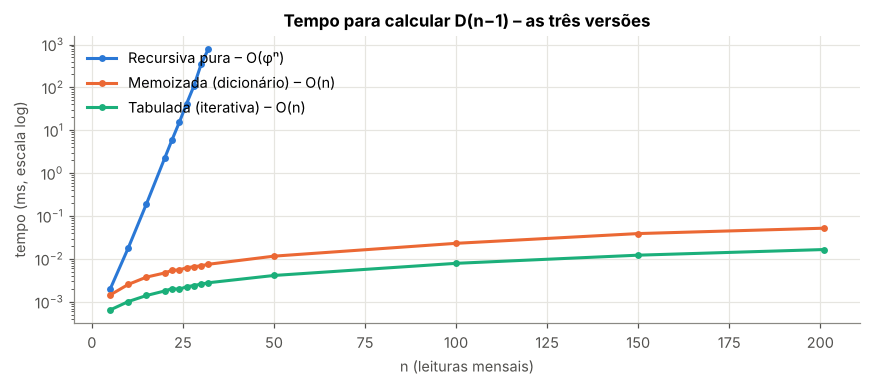

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for cor, col, nome in zip(CORES, ['recursiva_ms', 'memoizada_ms', 'tabulada_ms'],
                          ['Recursiva pura – O(φⁿ)', 'Memoizada (dicionário) – O(n)', 'Tabulada (iterativa) – O(n)']):
    b = bench.dropna(subset=[col])
    ax.plot(b.n, b[col], color=cor, marker='o', markersize=3.5, label=nome)
ax.set_yscale('log'); ax.set_xlabel('n (leituras mensais)'); ax.set_ylabel('tempo (ms, escala log)')
ax.set_title('Tempo para calcular D(n−1) – as três versões')
ax.legend(loc='upper left'); fig.tight_layout(); fig.savefig(FIGS / 'tempo_degradacao.png'); plt.show()

**Interpretação.** As três versões dão exatamente o mesmo valor em todas as 198 escadas (diferença 0,0), então a otimização não muda o resultado, só o custo. A recursiva pura cresce exatamente como Fibonacci: cada leitura a mais multiplica as chamadas por 1,618 (φ). Em n = 32 ela faz 11,4 milhões de chamadas e leva cerca de 0,65 s, enquanto a memoizada faz 65 chamadas e a tabulada 32 iterações; ambas ficam na casa dos microssegundos (cerca de 100 mil e 300 mil vezes mais rápidas). Na série completa de cada escada (n = 201 meses), a pura precisaria de ~10⁴² chamadas, algo como 10²⁷ anos, ou seja, é inviável. Entre as duas versões eficientes, a tabulada é cerca de 3× mais rápida que a memoizada, porque não paga o custo das chamadas de função nem das consultas ao dicionário, e não tem risco de estourar a pilha de recursão. É a versão usada no ranking.

### 2.3 Ranking de criticidade

In [8]:
ranking = ranking_criticidade(leituras, eventos, escadas)
ranking.to_csv(DATA / 'ranking_criticidade.csv', index=False)
print(f"Criticidade = D(n−1) na última leitura (set/2026). {len(ranking)} escadas ranqueadas.")
ranking.head(15)

Criticidade = D(n−1) na última leitura (set/2026). 198 escadas ranqueadas.


,posicao,escada,estacao,criticidade,eventos_12m,falhas_z1_12m,horas_paradas_12m
0,1,PIN-ER24,PIN,305.56,157,122,281.0
1,2,PTA-ER15,PTA,262.01,115,81,490.7
2,3,PIN-ER06,PIN,238.89,100,89,150.6
3,4,VSO-ER08,VSO,238.79,145,130,116.2
4,5,PTA-ER17,PTA,236.07,147,117,252.1
5,6,LUZ-ER04,LUZ,207.29,152,135,158.5
6,7,FRE-ER13,FRE,206.29,110,102,387.0
7,8,REP-ER59,REP,206.12,115,93,143.8
8,9,PIN-ER28,PIN,200.55,138,129,259.0
9,10,VSO-ER12,VSO,198.37,108,90,175.2


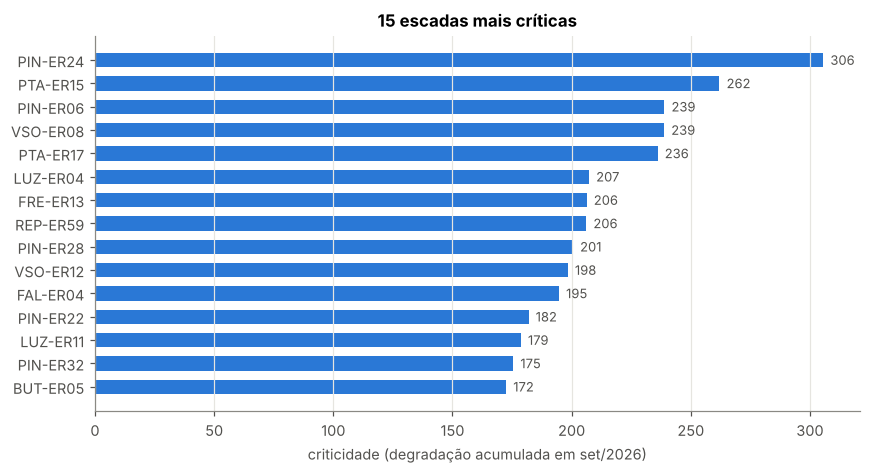

estacao            PIN  LUZ  PTA  BUT  FRE  VSO  REP  FAL  HIG  MBI
escadas no top 30    8    5    4    4    3    2    1    1    1    1


In [9]:
top = ranking.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(top.escada, top.criticidade, color=CORES[0], height=0.62)
for y, v in enumerate(top.criticidade):
    ax.text(v + 3, y, f'{v:.0f}', va='center', color='#52514e', fontsize=8.5)
ax.set_xlabel('criticidade (degradação acumulada em set/2026)'); ax.grid(axis='y', visible=False)
ax.set_title('15 escadas mais críticas'); fig.tight_layout(); fig.savefig(FIGS / 'ranking_top15.png'); plt.show()

print(ranking.head(30).estacao.value_counts().rename('escadas no top 30').to_frame().T.to_string())

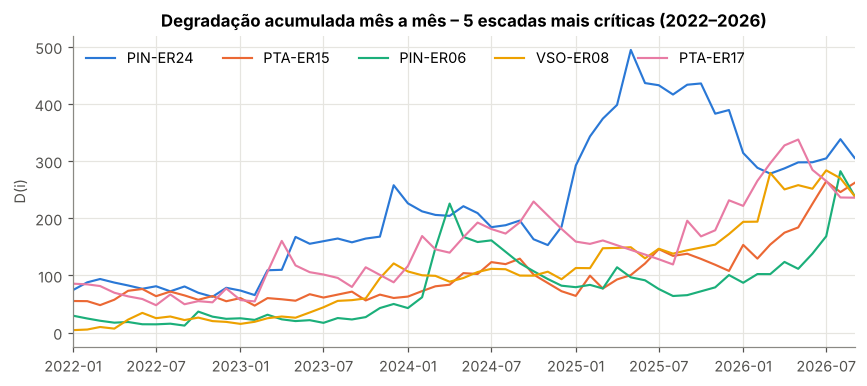

In [10]:
meses = leituras.columns.to_timestamp()
fig, ax = plt.subplots(figsize=(8, 3.6))
for cor, esc in zip(CORES, ranking.escada.head(5)):
    s = degradacao_tabulada(leituras.loc[esc].to_numpy(), serie=True)
    ax.plot(meses, s, color=cor, linewidth=1.4, label=esc)
ax.set_xlim(pd.Timestamp('2022-01-01'), meses[-1])
ax.set_ylabel('D(i)'); ax.set_title('Degradação acumulada mês a mês – 5 escadas mais críticas (2022–2026)')
ax.legend(loc='upper left', ncol=5); fig.tight_layout(); fig.savefig(FIGS / 'serie_top5.png'); plt.show()

**Sensibilidade aos coeficientes** – o ranking muda se o desgaste for "esquecido" mais rápido ou mais devagar?

In [11]:
base_top20 = set(ranking.escada.head(20))
sens = []
for a, b in [(0.3, 0.1), (0.6, 0.2), (0.8, 0.15)]:
    r = ranking_criticidade(leituras, eventos, escadas, a=a, b=b)
    corr = ranking.set_index('escada').posicao.corr(r.set_index('escada').posicao, method='spearman')
    sens.append({'a': a, 'b': b, 'top20_em_comum': len(base_top20 & set(r.escada.head(20))),
                 'spearman_vs_padrao': round(corr, 3), 'escada_n1': r.escada.iloc[0]})
pd.DataFrame(sens)

,a,b,top20_em_comum,spearman_vs_padrao,escada_n1
0,0.3,0.10,13,0.853,PTA-ER15
1,0.6,0.20,20,1.000,PIN-ER24
2,0.8,0.15,12,0.929,PIN-ER24


**Interpretação.** A escada mais crítica em set/2026 é a **PIN-ER24** (criticidade 305,6), com 157 eventos e 122 falhas corretivas nos últimos 12 meses. Em seguida vêm **PTA-ER15**, que tem a maior indisponibilidade do topo (491 horas paradas em 12 meses), e PIN-ER06, VSO-ER08 e PTA-ER17. Pinheiros concentra 8 das 30 escadas mais críticas, o que é coerente com ser a maior estação (32 escadas) e um ponto de integração com a CPTM. O gráfico mês a mês mostra que a criticidade é dinâmica: a PIN-ER24 teve pico em 2025 e vem caindo, enquanto VSO-ER08 e PIN-ER06 subiram com força em 2026 – o modelo reage a esse tipo de piora recente. Quanto à sensibilidade, o topo depende dos coeficientes: mudando (a, b) para "esquecer" mais rápido ou mais devagar, 12 a 13 das 20 primeiras continuam no top 20 e a correlação de Spearman fica entre 0,85 e 0,93. A ordem geral é robusta, mas as posições do meio da lista mudam. (a, b) = (0,6; 0,2) dá meia-vida de cerca de 4 meses, um meio-termo razoável para um plano de turno.

## 3. Rede de estações como grafo

`data/rede.json` modela **12 estações da Linha 4-Amarela** (operada pela Motiva) e **1 base de manutenção**
(Pátio Vila Sônia). Vértices = estações; arestas = trechos, com peso em **minutos de deslocamento da equipe**:
metrô entre estações vizinhas, acesso a pé do pátio e quatro ligações por viatura (rodoviárias) da base
até Butantã, Pinheiros, Paulista e Luz. Tempos e coordenadas são **estimativas** para fins acadêmicos.
Cada escada do dataset fica ligada à sua estação (`grafo.escadas`).

In [12]:
grafo = carregar_rede(DATA / 'rede.json', escadas)
print(f"{len(grafo.adj)} vértices, {len(grafo.arestas())} arestas\n")
print('Lista de adjacência (vizinho, minutos):')
for v, lst in grafo.adj.items():
    print(f"  {v:<4} → " + ', '.join(f'{w}({p})' for w, p, _ in lst))
print('\nEscadas ligadas a cada estação:')
for est, lst in grafo.escadas.items():
    print(f"  {est}: {len(lst):>2} escadas  ({', '.join(lst[:4])}{', …' if len(lst) > 4 else ''})")
assert sum(map(len, grafo.escadas.values())) == len(escadas)

13 vértices, 17 arestas

Lista de adjacência (vizinho, minutos):
  BASE → TVS(4), VSO(5), BUT(20), PIN(24), PTA(38), LUZ(50)
  TVS  → BASE(4), VSO(3)
  VSO  → BASE(5), TVS(3), MBI(3)
  MBI  → VSO(3), BUT(4)
  BUT  → MBI(4), PIN(2), BASE(20)
  PIN  → BUT(2), FAL(2), BASE(24)
  FAL  → PIN(2), FRA(2)
  FRA  → FAL(2), FRE(2)
  FRE  → FRA(2), PTA(2)
  PTA  → FRE(2), HIG(2), BASE(38)
  HIG  → PTA(2), REP(2)
  REP  → HIG(2), LUZ(2)
  LUZ  → REP(2), BASE(50)

Escadas ligadas a cada estação:
  BUT: 14 escadas  (BUT-ER01, BUT-ER02, BUT-ER03, BUT-ER04, …)
  FAL: 10 escadas  (FAL-ER01, FAL-ER02, FAL-ER03, FAL-ER04, …)
  FRA: 10 escadas  (FRA-ER01, FRA-ER02, FRA-ER03, FRA-ER04, …)
  FRE: 20 escadas  (FRE-ER01, FRE-ER02, FRE-ER03, FRE-ER04, …)
  HIG: 26 escadas  (HIG-ER01, HIG-ER02, HIG-ER03, HIG-ER04, …)
  LUZ: 20 escadas  (LUZ-ER01, LUZ-ER02, LUZ-ER03, LUZ-ER04, …)
  MBI: 13 escadas  (MBI-ER01, MBI-ER02, MBI-ER03, MBI-ER04, …)
  PIN: 32 escadas  (PIN-ER01, PIN-ER02, PIN-ER03, PIN-ER04, …)
  PTA: 1

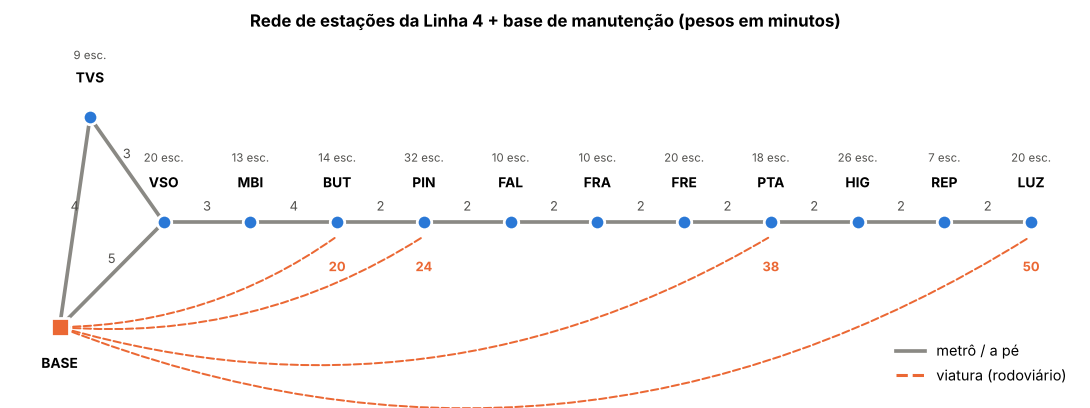

In [13]:
# Diagrama esquemático (posições didáticas; as coordenadas reais ficam no JSON para o A*)
linha = ['VSO', 'MBI', 'BUT', 'PIN', 'FAL', 'FRA', 'FRE', 'PTA', 'HIG', 'REP', 'LUZ']
pos = {s: (i + 1, 0) for i, s in enumerate(linha)}
pos['TVS'], pos['BASE'] = (0.15, 0.9), (-0.2, -0.9)
fig, ax = plt.subplots(figsize=(10, 3.8))
for u, v, p, modo in grafo.arestas():
    (x1, y1), (x2, y2) = pos[u], pos[v]
    if 'viatura' in modo:
        ax.annotate('', xy=(x2, y2 - 0.12), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle='-', color=CORES[1], lw=1.3, ls='--',
                                    connectionstyle=f'arc3,rad={0.12 + 0.012 * x2}'))
        ax.text(x2, y2 - 0.42, f'{p:g}', ha='center', fontsize=8.5, color=CORES[1], fontweight='bold')
    else:
        ax.plot([x1, x2], [y1, y2], color='#8a8984', lw=2.4, zorder=1)
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.1, f'{p:g}', ha='center', fontsize=8.5, color='#52514e')
for v, (x, y) in pos.items():
    eh_base = v == grafo.base
    ax.scatter(x, y, s=150 if eh_base else 90, color=CORES[1] if eh_base else CORES[0],
               marker='s' if eh_base else 'o', edgecolor='white', linewidth=1.8, zorder=3)
    n = len(grafo.escadas.get(v, []))
    ax.text(x, y + (0.3 if v != 'BASE' else -0.35), v, ha='center', fontsize=9, fontweight='bold')
    if n:
        ax.text(x, y + (0.52 if v != 'TVS' else 0.5), f'{n} esc.', ha='center', fontsize=7.5, color='#52514e')
ax.plot([], [], color='#8a8984', lw=2.4, label='metrô / a pé'); ax.plot([], [], color=CORES[1], ls='--', label='viatura (rodoviário)')
ax.set_title('Rede de estações da Linha 4 + base de manutenção (pesos em minutos)')
ax.legend(loc='lower right'); ax.axis('off'); ax.set_ylim(-1.5, 1.6)
fig.tight_layout(); fig.savefig(FIGS / 'rede.png'); plt.show()

### 3.1 BFS (menos trechos) × Dijkstra (menor tempo), partindo da base

In [14]:
saltos, pred_bfs, exp_bfs = bfs(grafo, grafo.base)
dist, pred_dij, exp_dij = dijkstra(grafo, grafo.base)
linhas = []
for v in grafo.adj:
    if v == grafo.base: continue
    r_bfs, r_dij = reconstruir_rota(pred_bfs, grafo.base, v), reconstruir_rota(pred_dij, grafo.base, v)
    linhas.append({'destino': v, 'BFS_trechos': saltos[v], 'BFS_minutos': custo_rota(grafo, r_bfs),
                   'BFS_rota': ' → '.join(r_bfs), 'Dijkstra_trechos': len(r_dij) - 1,
                   'Dijkstra_minutos': dist[v], 'Dijkstra_rota': ' → '.join(r_dij)})
rotas = pd.DataFrame(linhas)
rotas['ganho_min'] = rotas.BFS_minutos - rotas.Dijkstra_minutos
print(f"Vértices expandidos – BFS: {exp_bfs}, Dijkstra: {exp_dij}")
with pd.option_context('display.max_colwidth', 80):
    display(rotas)

Vértices expandidos – BFS: 13, Dijkstra: 13


,destino,BFS_trechos,BFS_minutos,BFS_rota,Dijkstra_trechos,Dijkstra_minutos,Dijkstra_rota,ganho_min
0,TVS,1,4,BASE → TVS,1,4.0,BASE → TVS,0.0
1,VSO,1,5,BASE → VSO,1,5.0,BASE → VSO,0.0
2,MBI,2,8,BASE → VSO → MBI,2,8.0,BASE → VSO → MBI,0.0
3,BUT,1,20,BASE → BUT,3,12.0,BASE → VSO → MBI → BUT,8.0
4,PIN,1,24,BASE → PIN,4,14.0,BASE → VSO → MBI → BUT → PIN,10.0
5,FAL,2,26,BASE → PIN → FAL,5,16.0,BASE → VSO → MBI → BUT → PIN → FAL,10.0
6,FRA,3,28,BASE → PIN → FAL → FRA,6,18.0,BASE → VSO → MBI → BUT → PIN → FAL → FRA,10.0
7,FRE,2,40,BASE → PTA → FRE,7,20.0,BASE → VSO → MBI → BUT → PIN → FAL → FRA → FRE,20.0
8,PTA,1,38,BASE → PTA,8,22.0,BASE → VSO → MBI → BUT → PIN → FAL → FRA → FRE → PTA,16.0
9,HIG,2,40,BASE → PTA → HIG,9,24.0,BASE → VSO → MBI → BUT → PIN → FAL → FRA → FRE → PTA → HIG,16.0


**Interpretação.** O BFS minimiza o **número de trechos** e, por isso, prefere as ligações diretas por viatura: até a Luz ele indica 1 trecho, mas 50 minutos. O Dijkstra minimiza o **tempo** e segue pela linha de metrô, com 11 trechos e apenas 28 minutos. Nas estações com ligação rodoviária ou perto delas, o caminho de menos trechos custa de 8 a 26 minutos a mais (FRE e REP são os piores casos). Para a equipe de manutenção, o critério que importa é o tempo, então as rotas do Dijkstra alimentam o plano do turno. O BFS continua útil quando o custo real é o número de baldeações ou transferências, por exemplo quando cada troca de modal exige liberação ou escolta.

## 4. Otimização de rotas com A\*

**Heurística:** `h(n) = distância_em_linha_reta(n, destino) / v_max`, em minutos, com
`v_max = max(distância_reta(u, v) / minutos(u, v))` sobre todas as arestas da rede.

* **Admissível** – nenhum caminho é mais curto que a linha reta e nenhum trecho é mais rápido que `v_max`;
  logo `h(n)` nunca superestima o tempo real até o destino, e o A\* devolve o caminho ótimo.
* **Consistente** – pela desigualdade triangular, `h(u) ≤ reta(u,v)/v_max + h(v) ≤ w(u,v) + h(v)`;
  cada vértice é fechado uma só vez, como no Dijkstra.
* **Por que tempo e não km** – o custo das arestas é em minutos; dividir por `v_max` põe a heurística na
  mesma unidade sem perder admissibilidade.

As duas propriedades são verificadas numericamente abaixo, para todos os pares de vértices.

In [15]:
v_max = velocidade_maxima(grafo)
print(f"v_max = {v_max:.3f} km/min ({v_max * 60:.0f} km/h)")
viol_adm = viol_cons = 0
for alvo in grafo.adj:
    h = heuristica_tempo(grafo, alvo, v_max)
    real, _, _ = dijkstra(grafo, alvo)
    viol_adm += sum(h(n) > real[n] + 1e-9 for n in grafo.adj)
    viol_cons += sum(h(u) > w + h(v) + 1e-9 for u, v, w, _ in grafo.arestas()) + \
                 sum(h(v) > w + h(u) + 1e-9 for u, v, w, _ in grafo.arestas())
print(f"Violações de admissibilidade: {viol_adm} | violações de consistência: {viol_cons}")

v_max = 0.677 km/min (41 km/h)
Violações de admissibilidade: 0 | violações de consistência: 0


In [16]:
def comparar(g, pares, rep=5):
    res = []
    for o, d in pares:
        hd = heuristica_tempo(g, d)
        dd, pdj, ed = dijkstra(g, o, d)
        da, pa, ea = a_estrela(g, o, d, hd)
        td = medir(lambda: dijkstra(g, o, d), rep); ta = medir(lambda: a_estrela(g, o, d, hd), rep)
        res.append({'origem': o, 'destino': d, 'custo_dijkstra': round(dd[d], 3), 'custo_A*': round(da[d], 3),
                    'mesma_rota': reconstruir_rota(pdj, o, d) == reconstruir_rota(pa, o, d),
                    'expandidos_dijkstra': ed, 'expandidos_A*': ea,
                    'tempo_dijkstra_us': td * 1e6, 'tempo_A*_us': ta * 1e6})
    return pd.DataFrame(res)

rede_cmp = comparar(grafo, [(grafo.base, v) for v in grafo.adj if v != grafo.base], rep=200)
assert (rede_cmp['custo_dijkstra'] == rede_cmp['custo_A*']).all()
rede_cmp.round(1)

,origem,destino,custo_dijkstra,custo_A*,mesma_rota,expandidos_dijkstra,expandidos_A*,tempo_dijkstra_us,tempo_A*_us
0,BASE,TVS,4.0,4.0,True,2,2,1.9,6.1
1,BASE,VSO,5.0,5.0,True,3,3,2.2,6.7
2,BASE,MBI,8.0,8.0,True,4,4,2.9,7.8
3,BASE,BUT,12.0,12.0,True,5,5,3.6,9.1
4,BASE,PIN,14.0,14.0,True,6,6,4.1,10.3
5,BASE,FAL,16.0,16.0,True,7,7,4.9,11.8
6,BASE,FRA,18.0,18.0,True,8,8,5.2,12.9
7,BASE,FRE,20.0,20.0,True,9,9,6.2,14.0
8,BASE,PTA,22.0,22.0,True,10,10,6.9,15.7
9,BASE,HIG,24.0,24.0,True,11,11,7.5,17.1


Na rede real o grafo é praticamente uma linha – só existe um caminho bom até cada estação –, então há pouco
espaço para a heurística podar. Para medir o A\* onde ele faz diferença, o mesmo código roda numa **grade
sintética de 3.600 vértices** (60 × 60, ~0,5 km entre vizinhos, pesos com fator de trânsito aleatório),
com 150 pares origem–destino sorteados.

In [17]:
grade = grade_sintetica(60)
rnd = random.Random(7)
nos = list(grade.adj)
pares = [tuple(rnd.sample(nos, 2)) for _ in range(150)]
grade_cmp = comparar(grade, pares, rep=1)
assert (grade_cmp['custo_dijkstra'] - grade_cmp['custo_A*']).abs().max() < 1e-6
resumo_ast = pd.DataFrame({
    'rede': ['Linha 4 (13 vértices)', 'Grade sintética (3.600 vértices)'],
    'pares': [len(rede_cmp), len(grade_cmp)],
    'custos_iguais': [True, True],
    'expandidos_dijkstra_medio': [rede_cmp['expandidos_dijkstra'].mean(), grade_cmp['expandidos_dijkstra'].mean()],
    'expandidos_A*_medio': [rede_cmp['expandidos_A*'].mean(), grade_cmp['expandidos_A*'].mean()],
    'tempo_dijkstra_ms_medio': [rede_cmp['tempo_dijkstra_us'].mean() / 1e3, grade_cmp['tempo_dijkstra_us'].mean() / 1e3],
    'tempo_A*_ms_medio': [rede_cmp['tempo_A*_us'].mean() / 1e3, grade_cmp['tempo_A*_us'].mean() / 1e3]})
resumo_ast['reducao_expandidos_%'] = 100 * (1 - resumo_ast['expandidos_A*_medio'] / resumo_ast['expandidos_dijkstra_medio'])
resumo_ast['reducao_tempo_%'] = 100 * (1 - resumo_ast['tempo_A*_ms_medio'] / resumo_ast['tempo_dijkstra_ms_medio'])
resumo_ast.round(3)

,rede,pares,custos_iguais,expandidos_dijkstra_medio,expandidos_A*_medio,tempo_dijkstra_ms_medio,tempo_A*_ms_medio,reducao_expandidos_%,reducao_tempo_%
0,Linha 4 (13 vértices),12,True,7.500,7.50,0.005,0.012,0.000,-140.406
1,Grade sintética (3.600 vértices),150,True,1809.653,727.94,2.650,2.211,59.775,16.562


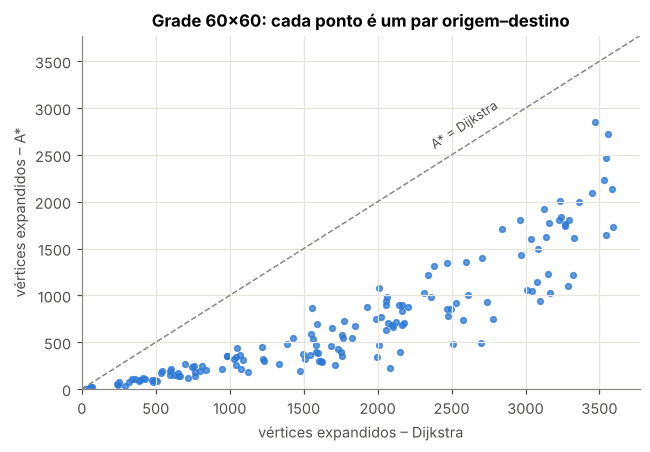

In [18]:
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.scatter(grade_cmp['expandidos_dijkstra'], grade_cmp['expandidos_A*'], s=14, color=CORES[0], alpha=0.75)
lim = grade_cmp['expandidos_dijkstra'].max() * 1.05
ax.plot([0, lim], [0, lim], color='#8a8984', linewidth=1, linestyle='--')
ax.text(lim * 0.62, lim * 0.68, 'A* = Dijkstra', color='#52514e', fontsize=8.5, rotation=33)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel('vértices expandidos – Dijkstra'); ax.set_ylabel('vértices expandidos – A*')
ax.set_title('Grade 60×60: cada ponto é um par origem–destino')
fig.tight_layout(); fig.savefig(FIGS / 'astar_vs_dijkstra.png'); plt.show()

**Interpretação.** A heurística passou nos testes de admissibilidade e consistência em todos os pares (0 violações), e o A\* encontrou sempre o mesmo custo do Dijkstra. Na **rede real** não houve ganho: o grafo é praticamente uma linha, então só existe um caminho bom até cada estação, e os dois algoritmos expandem os mesmos vértices. O A\* chega a ser 2 a 2,5× mais lento, porque calcula a heurística (haversine) a cada vizinho. Na **grade de 3.600 vértices**, onde há muitos caminhos alternativos, o A\* expandiu em média 60 % menos vértices (728 contra 1.810) e foi cerca de 17 % mais rápido. O ganho de tempo é menor que o de expansões por causa do custo da heurística. Conclusão: para a rede atual da Linha 4 o Dijkstra basta; o A\* passa a compensar se a rede crescer (outras linhas da Motiva, malha viária completa para as viaturas) ou se for preciso consultar muitos pares origem–destino.

## 5. Plano de manutenção – `planejar_turno(base, horas)`

1. **Candidatas:** as 40 escadas mais críticas do ranking.
2. **Tempo de reparo:** mediana das falhas com indisponibilidade de cada escada nos últimos 24 meses
   (limitada a 20–240 min) + 10 min de acesso interno.
3. **Mochila por grupos (programação dinâmica):** cada estação é um grupo e a opção *k* é atender as *k* escadas
   mais críticas dali; custo = ida e volta da base (Dijkstra) + reparos, valor = soma das criticidades.
4. **Rota real:** estações escolhidas em ordem de vizinho mais próximo, caminhos reconstruídos pelo Dijkstra,
   volta à base incluída.
5. **Refinamento:** a folga entre o custo conservador e a rota real é usada para incluir mais escadas críticas.

In [19]:
contexto = {'grafo': grafo, 'ranking': ranking, 'reparo': tempos_reparo(eventos)}
planos = {}
for horas in (4, 8, 12):
    planos[horas] = planejar_turno('BASE', horas, contexto)
    exibir_plano(planos[horas]); print()

Turno de 4 h saindo de BASE (orçamento 240 min)
------------------------------------------------------------------------------
 1. 07:05  Vila Sônia (VSO)  +5 min  rota: BASE → VSO
      07:05  VSO-ER08  criticidade 238.79   reparo  38 min
      07:43  VSO-ER12  criticidade 198.37   reparo  47 min
 2. 08:39  Pinheiros (PIN)  +9 min  rota: VSO → MBI → BUT → PIN
      08:39  PIN-ER24  criticidade 305.56   reparo  36 min
      09:15  PIN-ER06  criticidade 238.89   reparo  41 min
      09:56  PIN-ER28  criticidade 200.55   reparo  30 min
    10:40  retorno à base  +14 min  rota: PIN → BUT → MBI → VSO → BASE
------------------------------------------------------------------------------
Escadas atendidas: 5 | criticidade atendida: 1182.16 | tempo usado: 220 de 240 min (deslocamento 28, reparo 192)

Turno de 8 h saindo de BASE (orçamento 480 min)
------------------------------------------------------------------------------
 1. 07:05  Vila Sônia (VSO)  +5 min  rota: BASE → VSO
      07:05  VS

In [20]:
resumo_turnos = pd.DataFrame([{
    'turno_h': h, 'escadas_atendidas': p['escadas_atendidas'], 'estacoes': len(p['paradas']),
    'tempo_usado_min': p['tempo_total_min'], 'orcamento_min': p['orcamento_min'],
    'deslocamento_min': p['tempo_deslocamento_min'], 'reparo_min': p['tempo_reparo_min'],
    'criticidade_atendida': p['criticidade_atendida'],
    '%_criticidade_top40': 100 * p['criticidade_atendida'] / ranking.head(40).criticidade.sum()}
    for h, p in planos.items()])
assert (resumo_turnos.tempo_usado_min <= resumo_turnos.orcamento_min).all()
# coerência: as escadas atendidas são do topo do ranking?
pos = ranking.set_index('escada').posicao
for h, p in planos.items():
    atend = [s['escada'] for par in p['paradas'] for s in par['escadas']]
    print(f"{h:>2} h – posições no ranking das escadas atendidas: {sorted(pos[atend].tolist())}")
resumo_turnos.round(1)

 4 h – posições no ranking das escadas atendidas: [1, 3, 4, 9, 10]
 8 h – posições no ranking das escadas atendidas: [1, 2, 3, 4, 5, 6, 9, 10, 15, 20, 26]
12 h – posições no ranking das escadas atendidas: [1, 2, 3, 4, 5, 6, 7, 8, 9, 13, 15, 16, 17, 20, 23, 26, 27, 28]


,turno_h,escadas_atendidas,estacoes,tempo_usado_min,orcamento_min,deslocamento_min,reparo_min,criticidade_atendida,%_criticidade_top40
0,4,5,2,220.0,240,28.0,192,1182.2,17.4
1,8,11,5,455.0,480,56.0,399,2366.6,34.9
2,12,18,7,696.0,720,56.0,640,3530.6,52.1


**Interpretação.** O plano respeita o orçamento nos três cenários: 220 de 240 min (4 h), 455 de 480 min (8 h) e 696 de 720 min (12 h). Ele é coerente com o ranking: em 4 h a equipe atende 5 escadas, todas entre as 10 mais críticas (posições 1, 3, 4, 9 e 10), concentradas em Vila Sônia e Pinheiros, perto da base. Em 8 h o plano chega a Paulista e Luz e atende as 6 primeiras do ranking. O deslocamento é pequeno (28 a 56 min), porque a rota segue a linha e volta pelo menor caminho, então quase todo o turno vai para reparo. Nem sempre a ordem do ranking é seguida à risca: em 12 h a VSO-ER12 (10ª, 47 min de reparo) fica de fora e entram escadas das posições 23 a 28, com reparos mais curtos. Isso é a mochila maximizando a criticidade **total** atendida no tempo disponível, que é o objetivo de um turno. Limitações: os tempos de reparo são medianas históricas, os tempos de deslocamento são estimativas, e o plano supõe uma única equipe; com mais equipes, bastaria rodar a mochila por equipe com as estações divididas.

## 6. Conclusões

1. **Programação dinâmica é obrigatória aqui.** A recorrência de degradação com dois termos torna a recursão pura exponencial (×1,618 por leitura). Memoização e tabulação resolvem as 198 escadas × 201 meses em milissegundos, com resultado idêntico; a tabulada é a mais rápida e segura.
2. **O ranking aponta Pinheiros, Paulista e Vila Sônia** como as estações com as escadas mais críticas; a PIN-ER24 lidera. Mudar os coeficientes altera o meio da lista, mas mantém o grupo do topo.
3. **Dijkstra é o algoritmo certo para a equipe**: o BFS economiza trechos, mas custa até 26 min a mais por viagem.
4. **A\* é correto e só compensa em redes maiores**: na Linha 4 (uma linha) não poda nada; numa malha de 3.600 vértices expande 60 % menos.
5. **`planejar_turno` integra tudo**: usa o ranking como valor, o Dijkstra como custo de deslocamento e uma mochila por programação dinâmica para escolher as escadas, sempre dentro do turno.

**Limitações e próximos passos:** os dados são notas de manutenção, não sensores; com telemetria real, bastaria trocar `dano_evento` pelos sinais de vibração, temperatura, corrente, óleo e velocidade, sem mudar o restante. Os tempos da rede são estimados e deveriam ser calibrados com a operação. A quebra de registro em 2023 recomenda recalibrar os pesos com dados apenas desse período.